In [ ]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score
)

print("Environment ready for customer review analysis.")


Environment ready for customer review analysis.


In [ ]:
#upload a dataset

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

if file_name.lower().endswith(".csv"):
    df = pd.read_csv(file_name)
elif file_name.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(file_name)
else:
    raise ValueError("Please upload a CSV or Excel dataset.")

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumns:", df.columns.tolist())


Saving Amazon Review Data Web Scrapping - Amazon Review Data Web Scrapping.csv to Amazon Review Data Web Scrapping - Amazon Review Data Web Scrapping.csv
Dataset shape: (60889, 6)


,Unique_ID,Category,Review_Header,Review_text,Rating,Own_Rating
0,136040,smartTv,Nice one,I liked it,5,Positive
1,134236,mobile,Huge battery life with amazing display,I bought the phone on Amazon and been using my...,5,Positive
2,113945,books,Four Stars,"Awesome book at reasonable price, must buy ......",4,Positive
3,168076,smartTv,Nice quality,good,5,Positive
4,157302,books,Nice book,"The book is fine,not bad,contains nice concept...",3,Neutral



Columns: ['Unique_ID', 'Category', 'Review_Header', 'Review_text', 'Rating', 'Own_Rating']


In [ ]:

print("Dataset information:")
df.info()

print("\nMissing values per column:")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .to_frame("Missing Values")
)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSample reviews:")
display(df.sample(min(5, len(df)), random_state=42))


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60889 entries, 0 to 60888
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Unique_ID      60889 non-null  int64 
 1   Category       60889 non-null  object
 2   Review_Header  60884 non-null  object
 3   Review_text    60857 non-null  object
 4   Rating         60889 non-null  int64 
 5   Own_Rating     60889 non-null  object
dtypes: int64(2), object(4)
memory usage: 2.8+ MB

Missing values per column:


,Missing Values
Review_text,32
Review_Header,5
Category,0
Unique_ID,0
Rating,0
Own_Rating,0



Duplicate rows: 0

Sample reviews:


,Unique_ID,Category,Review_Header,Review_text,Rating,Own_Rating
9998,123332,mobile accessories,Love it,Fabulous,5,Positive
31306,129639,smartTv,Nice one for small budget,Good product,4,Positive
29066,154821,mobile accessories,Unremarkable camera.,"Sound is average. Camera is pathetic, battery ...",3,Neutral
18603,162856,smartTv,Good,Very good,5,Positive
43932,113951,books,Awesome personal improvement guide,"Awesome book for self improvement, after readi...",5,Positive


Dataset shape: (60889, 6)

Sentiment label distribution:


,Review Count,Percentage
Own_Rating,,
Positive,47436,77.91
Negative,9087,14.92
Neutral,4366,7.17



Numerical rating distribution:


,Review Count
Rating,
1,6979
2,2108
3,4366
4,12976
5,34460


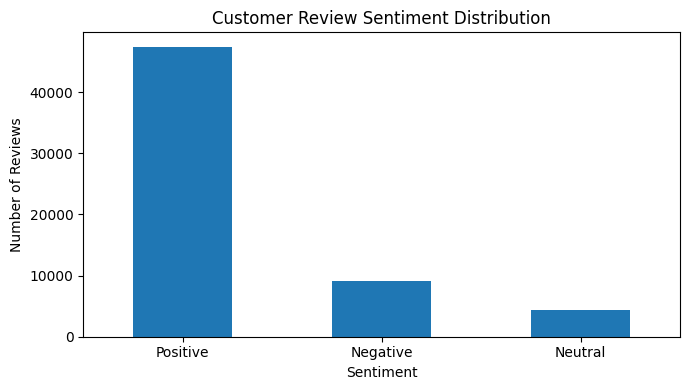

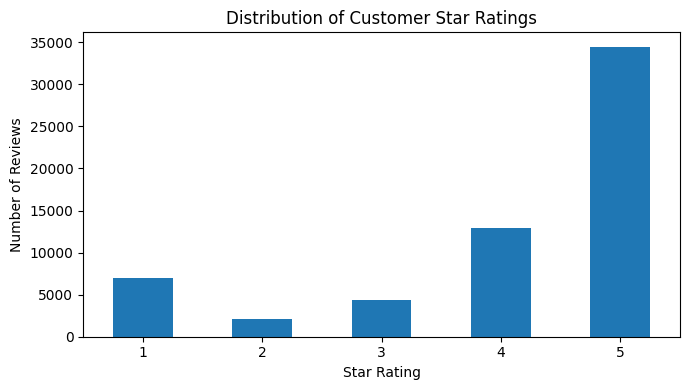

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Check dataset size and target labels
print("Dataset shape:", df.shape)

print("\nSentiment label distribution:")
display(
    df["Own_Rating"]
      .value_counts(dropna=False)
      .to_frame("Review Count")
      .assign(
          Percentage=lambda x:
          (x["Review Count"] / len(df) * 100).round(2)
      )
)

print("\nNumerical rating distribution:")
display(
    df["Rating"]
      .value_counts()
      .sort_index()
      .to_frame("Review Count")
)

# Visualise sentiment distribution
df["Own_Rating"].value_counts().plot(
    kind="bar",
    figsize=(7, 4),
    rot=0
)
plt.title("Customer Review Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

# Visualise star ratings
df["Rating"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(7, 4),
    rot=0
)
plt.title("Distribution of Customer Star Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


In [ ]:

# Compare the existing sentiment labels with star ratings
sentiment_rating_table = pd.crosstab(
    df["Rating"],
    df["Own_Rating"],
    normalize="index"
).round(3)

print("Sentiment labels within each star rating:")
display(sentiment_rating_table)

print("\nUnique sentiment labels:")
print(sorted(df["Own_Rating"].dropna().unique()))


Sentiment labels within each star rating:


Own_Rating,Negative,Neutral,Positive
Rating,,,
1,1.0,0.0,0.0
2,1.0,0.0,0.0
3,0.0,1.0,0.0
4,0.0,0.0,1.0
5,0.0,0.0,1.0



Unique sentiment labels:
['Negative', 'Neutral', 'Positive']


In [ ]:

print("Rows with missing review text:")
display(
    df.loc[
        df["Review_text"].isna(),
        ["Category", "Review_Header", "Review_text",
         "Rating", "Own_Rating"]
    ].head(10)
)

print("\nRows with missing review headers:")
display(
    df.loc[
        df["Review_Header"].isna(),
        ["Category", "Review_text", "Rating", "Own_Rating"]
    ].head(10)
)


Rows with missing review text:


,Category,Review_Header,Review_text,Rating,Own_Rating
655,refrigerator,Five Stars,NaN,5,Positive
2869,mobile,NaN,NaN,5,Positive
9021,mobile,Perfect phone; perfect camera 😍,NaN,5,Positive
11244,smartTv,Five Stars,NaN,5,Positive
14885,books,Five Stars,NaN,5,Positive
16298,mobile,NaN,NaN,4,Positive
16434,refrigerator,Superb is the word. Stunning photos. Easy inte...,NaN,5,Positive
17801,refrigerator,Five Stars,NaN,5,Positive
18679,smartTv,Five Stars,NaN,5,Positive
19425,smartTv,Received without a bill.,NaN,2,Negative



Rows with missing review headers:


,Category,Review_text,Rating,Own_Rating
2869,mobile,NaN,5,Positive
14350,mobile,Battery life,3,Neutral
16298,mobile,NaN,4,Positive
55664,mobile,NaN,4,Positive
59099,mobile,Awesome phone.,5,Positive


In [ ]:

import pandas as pd

# Keep the original dataset unchanged
reviews = df.copy()

# Replace missing text with empty strings and remove whitespace
reviews["Review_Header"] = (
    reviews["Review_Header"].fillna("").astype(str).str.strip()
)
reviews["Review_text"] = (
    reviews["Review_text"].fillna("").astype(str).str.strip()
)

# Combine title and review body
reviews["Review_Content"] = (
    reviews["Review_Header"] + " " + reviews["Review_text"]
).str.strip()

# Remove records with no usable review content
before = len(reviews)

reviews = reviews[
    reviews["Review_Content"].str.len() > 0
].copy()

# Remove rows without a sentiment label
reviews = reviews.dropna(subset=["Own_Rating"]).copy()

print("Rows before cleaning:", before)
print("Rows after cleaning:", len(reviews))
print("Rows removed:", before - len(reviews))
print("Missing review content:", reviews["Review_Content"].eq("").sum())
print("\nSentiment distribution:")
display(reviews["Own_Rating"].value_counts().to_frame("Count"))

display(
    reviews[["Review_Header", "Review_text",
             "Review_Content", "Rating", "Own_Rating"]].head(10)
)


Rows before cleaning: 60889
Rows after cleaning: 60886
Rows removed: 3
Missing review content: 0

Sentiment distribution:


,Count
Own_Rating,
Positive,47433
Negative,9087
Neutral,4366


,Review_Header,Review_text,Review_Content,Rating,Own_Rating
0,Nice one,I liked it,Nice one I liked it,5,Positive
1,Huge battery life with amazing display,I bought the phone on Amazon and been using my...,Huge battery life with amazing display I bough...,5,Positive
2,Four Stars,"Awesome book at reasonable price, must buy ......","Four Stars Awesome book at reasonable price, m...",4,Positive
3,Nice quality,good,Nice quality good,5,Positive
4,Nice book,"The book is fine,not bad,contains nice concept...","Nice book The book is fine,not bad,contains ni...",3,Neutral
5,Nice tv,Nice tv and pic quality .good custmer srrvice ...,Nice tv Nice tv and pic quality .good custmer ...,5,Positive
6,Beauty and the Beast,The iPhone 7 is legitimately among the most in...,Beauty and the Beast The iPhone 7 is legitimat...,5,Positive
7,"20000 mAH, what more you need","20000 mAH, what more you need. Super product","20000 mAH, what more you need 20000 mAH, what ...",5,Positive
8,Need more good quality,The company should give more Bettany backup an...,Need more good quality The company should give...,2,Negative
9,Good phone,Very good phone,Good phone Very good phone,5,Positive


In [ ]:

print("Rating vs existing sentiment label:")
display(pd.crosstab(reviews["Rating"], reviews["Own_Rating"]))

print("\nSentiment labels:")
print(reviews["Own_Rating"].value_counts(normalize=True).mul(100).round(2))

print("\nRating range:")
print(reviews["Rating"].min(), "to", reviews["Rating"].max())


Rating vs existing sentiment label:


Own_Rating,Negative,Neutral,Positive
Rating,,,
1,6979,0,0
2,2108,0,0
3,0,4366,0
4,0,0,12974
5,0,0,34459



Sentiment labels:
Own_Rating
Positive    77.90
Negative    14.92
Neutral      7.17
Name: proportion, dtype: float64

Rating range:
1 to 5


Training reviews: 48708
Testing reviews: 12178


,Model,Accuracy,Macro F1,Weighted F1
0,Majority baseline,0.7790,0.2919,0.6823
1,TF-IDF + Logistic Regression,0.8432,0.6779,0.8581



Classification report:
              precision    recall  f1-score   support

    Negative       0.74      0.83      0.78      1818
     Neutral       0.27      0.44      0.33       873
    Positive       0.96      0.88      0.92      9487

    accuracy                           0.84     12178
   macro avg       0.66      0.72      0.68     12178
weighted avg       0.88      0.84      0.86     12178



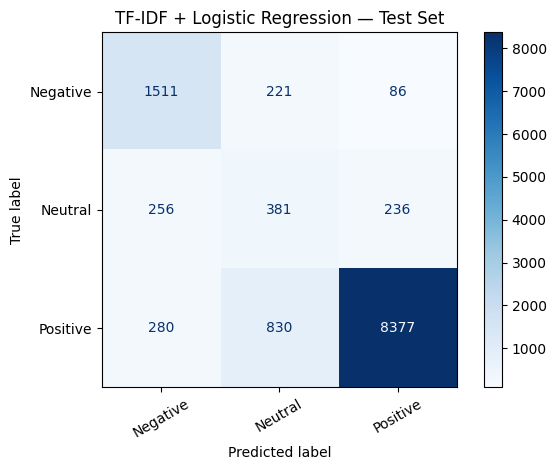

In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

# Features: review text only
X = reviews["Review_Content"]
y = reviews["Own_Rating"]

# Stratified split preserves class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

# Majority-class baseline
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)
dummy_predictions = dummy_model.predict(X_test)

# TF-IDF + Logistic Regression
nlp_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        ngram_range=(1, 2),
        min_df=2,
        max_features=100_000,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

nlp_model.fit(X_train, y_train)
predictions = nlp_model.predict(X_test)

# Compare overall metrics
results = pd.DataFrame({
    "Model": ["Majority baseline", "TF-IDF + Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_test, dummy_predictions),
        accuracy_score(y_test, predictions)
    ],
    "Macro F1": [
        f1_score(y_test, dummy_predictions, average="macro"),
        f1_score(y_test, predictions, average="macro")
    ],
    "Weighted F1": [
        f1_score(y_test, dummy_predictions, average="weighted"),
        f1_score(y_test, predictions, average="weighted")
    ]
})

display(results.round(4))

print("\nClassification report:")
print(classification_report(
    y_test,
    predictions,
    labels=["Negative", "Neutral", "Positive"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    labels=["Negative", "Neutral", "Positive"],
    display_labels=["Negative", "Neutral", "Positive"],
    cmap="Blues",
    xticks_rotation=30
)
plt.title("TF-IDF + Logistic Regression — Test Set")
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support
)
import pandas as pd

# Split the existing training data into training and validation sets
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    ),
    "Multinomial Naive Bayes": MultinomialNB(
        alpha=0.5
    )
}

validation_results = []
trained_models = {}

for name, classifier in models.items():
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            strip_accents="unicode",
            ngram_range=(1, 2),
            min_df=2,
            max_features=100_000,
            sublinear_tf=True
        )),
        ("classifier", classifier)
    ])

    pipeline.fit(X_subtrain, y_subtrain)
    val_predictions = pipeline.predict(X_val)
    trained_models[name] = pipeline

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_val,
        val_predictions,
        labels=["Negative", "Neutral", "Positive"],
        zero_division=0
    )

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, val_predictions),
        "Macro F1": f1_score(
            y_val, val_predictions, average="macro"
        ),
        "Negative F1": f1[0],
        "Neutral F1": f1[1],
        "Neutral Recall": recall[1],
        "Positive F1": f1[2]
    })

validation_df = pd.DataFrame(validation_results)
display(
    validation_df.sort_values(
        "Macro F1", ascending=False
    ).round(4)
)


,Model,Accuracy,Macro F1,Negative F1,Neutral F1,Neutral Recall,Positive F1
0,Logistic Regression,0.8463,0.6880,0.7874,0.3554,0.4721,0.9213
1,Linear SVM,0.8777,0.6735,0.7949,0.2845,0.2461,0.9410
2,Multinomial Naive Bayes,0.8613,0.5445,0.7033,0.0085,0.0043,0.9217


In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support
)
import numpy as np
import pandas as pd

# Fit TF-IDF only on the training portion
tfidf = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    min_df=2,
    max_features=100_000,
    sublinear_tf=True
)

X_subtrain_tfidf = tfidf.fit_transform(X_subtrain)
X_val_tfidf = tfidf.transform(X_val)

classes = np.array(["Negative", "Neutral", "Positive"])

# Calculate balanced weights from training labels only
balanced_values = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_subtrain
)

balanced_weights = dict(zip(classes, balanced_values))

print("Balanced class weights:", balanced_weights)

# Test neutral weighting and regularisation
experiments = []

for neutral_multiplier in [1.0, 1.5, 2.0, 3.0]:
    weights = balanced_weights.copy()
    weights["Neutral"] *= neutral_multiplier

    for c_value in [0.5, 1.0, 2.0]:
        model = LogisticRegression(
            C=c_value,
            class_weight=weights,
            max_iter=1000,
            random_state=42
        )

        model.fit(X_subtrain_tfidf, y_subtrain)
        val_pred = model.predict(X_val_tfidf)

        precision, recall, f1, _ = (
            precision_recall_fscore_support(
                y_val,
                val_pred,
                labels=classes,
                zero_division=0
            )
        )

        experiments.append({
            "Neutral weight multiplier": neutral_multiplier,
            "C": c_value,
            "Accuracy": accuracy_score(y_val, val_pred),
            "Macro F1": f1_score(
                y_val, val_pred, average="macro"
            ),
            "Neutral precision": precision[1],
            "Neutral recall": recall[1],
            "Neutral F1": f1[1]
        })

tuning_results = pd.DataFrame(experiments)

display(
    tuning_results.sort_values(
        "Macro F1", ascending=False
    ).round(4)
)


Balanced class weights: {np.str_('Negative'): np.float64(2.2336486099168815), np.str_('Neutral'): np.float64(4.648771176330231), np.str_('Positive'): np.float64(0.42786397426183964)}


,Neutral weight multiplier,C,Accuracy,Macro F1,Neutral precision,Neutral recall,Neutral F1
1,1.0,1.0,0.8463,0.6880,0.2850,0.4721,0.3554
2,1.0,2.0,0.8531,0.6865,0.2889,0.4249,0.3439
0,1.0,0.5,0.8390,0.6857,0.2748,0.5064,0.3563
5,1.5,2.0,0.8193,0.6687,0.2352,0.4950,0.3189
4,1.5,1.0,0.8097,0.6678,0.2315,0.5551,0.3267
3,1.5,0.5,0.7972,0.6668,0.2268,0.6195,0.3321
8,2.0,2.0,0.8090,0.6641,0.2249,0.5265,0.3152
7,2.0,1.0,0.7949,0.6608,0.2188,0.5951,0.3200
6,2.0,0.5,0.7783,0.6569,0.2144,0.6738,0.3253
11,3.0,2.0,0.7853,0.6532,0.2060,0.5794,0.3039


FINAL TEST RESULTS
Accuracy:  0.8432
Macro F1:  0.6779
Weighted F1: 0.8581

Classification Report:
              precision    recall  f1-score   support

    Negative       0.74      0.83      0.78      1818
     Neutral       0.27      0.44      0.33       873
    Positive       0.96      0.88      0.92      9487

    accuracy                           0.84     12178
   macro avg       0.66      0.72      0.68     12178
weighted avg       0.88      0.84      0.86     12178



,Predicted Negative,Predicted Neutral,Predicted Positive
Actual Negative,1511,221,86
Actual Neutral,256,381,236
Actual Positive,280,830,8377


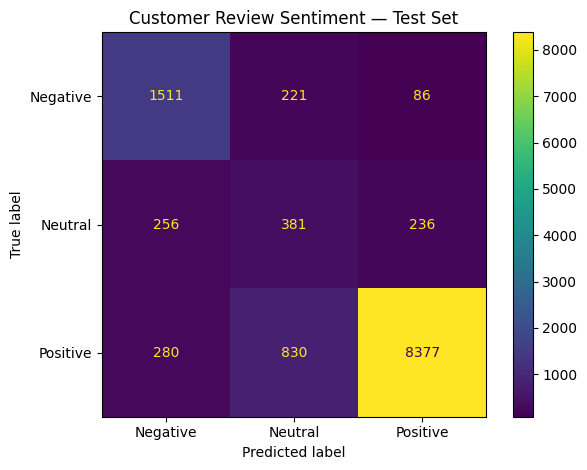

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

# 1. Fit TF-IDF on the full training set only
final_tfidf = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    min_df=2,
    max_features=100_000,
    sublinear_tf=True
)

X_train_tfidf = final_tfidf.fit_transform(X_train)
X_test_tfidf = final_tfidf.transform(X_test)

# 2. Train the selected Logistic Regression model
final_model = LogisticRegression(
    C=1.0,
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

final_model.fit(X_train_tfidf, y_train)

# 3. Evaluate on the held-out test set
test_pred = final_model.predict(X_test_tfidf)

print("FINAL TEST RESULTS")
print("=" * 50)
print(f"Accuracy:  {accuracy_score(y_test, test_pred):.4f}")
print(f"Macro F1:  {f1_score(y_test, test_pred, average='macro'):.4f}")
print(f"Weighted F1: {f1_score(y_test, test_pred, average='weighted'):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, test_pred, zero_division=0))

# 4. Confusion matrix
labels = ["Negative", "Neutral", "Positive"]

cm = confusion_matrix(y_test, test_pred, labels=labels)
cm_df = pd.DataFrame(
    cm,
    index=[f"Actual {label}" for label in labels],
    columns=[f"Predicted {label}" for label in labels]
)

display(cm_df)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(values_format="d")

plt.title("Customer Review Sentiment — Test Set")
plt.tight_layout()
plt.show()

In [ ]:

import numpy as np
import pandas as pd

feature_names = final_tfidf.get_feature_names_out()
class_names = final_model.classes_
coefficients = final_model.coef_

for class_index, sentiment in enumerate(class_names):
    class_coefficients = coefficients[class_index]

    top_indices = np.argsort(class_coefficients)[-15:][::-1]

    print(f"\nTop terms associated with {sentiment} reviews")
    print("-" * 45)

    top_terms = pd.DataFrame({
        "Term": feature_names[top_indices],
        "Model coefficient": class_coefficients[top_indices]
    })

    display(top_terms.round(3))



Top terms associated with Negative reviews
---------------------------------------------


,Term,Model coefficient
0,worst,5.776
1,one star,5.072
2,not,4.843
3,two stars,4.366
4,waste,3.855
5,poor,3.797
6,pathetic,3.685
7,defective,3.679
8,return,3.671
9,bad,3.597



Top terms associated with Neutral reviews
---------------------------------------------


,Term,Model coefficient
0,three stars,5.365
1,average,3.650
2,three,3.636
3,not,3.387
4,good,2.675
5,awesome awesome,2.620
6,okay,2.344
7,but,2.271
8,excited,1.976
9,ok,1.966



Top terms associated with Positive reviews
---------------------------------------------


,Term,Model coefficient
0,awesome,5.865
1,amazing,5.417
2,best,5.211
3,excellent,4.735
4,great,4.324
5,superb,3.874
6,perfect,3.741
7,love,3.522
8,five,3.457
9,good,3.341


Largest categories by review volume


,Category,Total_Reviews,Negative_Reviews,Neutral_Reviews,Positive_Reviews,Negative_Share_%,Neutral_Share_%,Positive_Share_%
1,mobile,22746,3494,1736,17516,15.36,7.63,77.01
2,mobile accessories,14811,2436,1231,11144,16.45,8.31,75.24
4,smartTv,14624,2364,935,11325,16.17,6.39,77.44
3,refrigerator,4791,586,275,3930,12.23,5.74,82.03
0,books,3914,207,189,3518,5.29,4.83,89.88



Categories with the highest negative-review share


,Category,Total_Reviews,Negative_Reviews,Neutral_Reviews,Positive_Reviews,Negative_Share_%,Neutral_Share_%,Positive_Share_%
2,mobile accessories,14811,2436,1231,11144,16.45,8.31,75.24
4,smartTv,14624,2364,935,11325,16.17,6.39,77.44
1,mobile,22746,3494,1736,17516,15.36,7.63,77.01
3,refrigerator,4791,586,275,3930,12.23,5.74,82.03
0,books,3914,207,189,3518,5.29,4.83,89.88


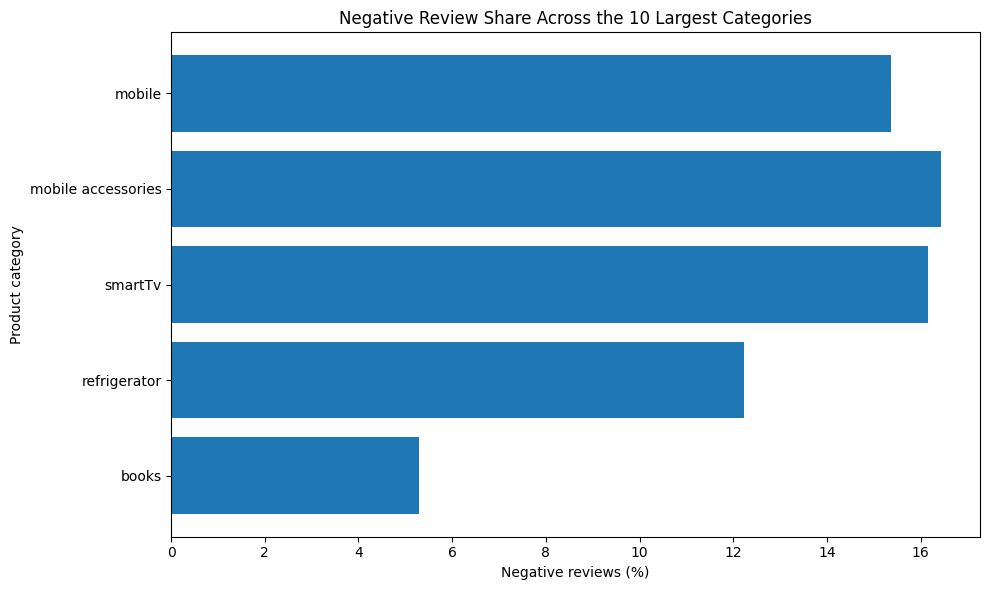

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Review volume and sentiment distribution by category
category_summary = (
    reviews.groupby("Category")
    .agg(
        Total_Reviews=("Own_Rating", "size"),
        Negative_Reviews=("Own_Rating", lambda s: (s == "Negative").sum()),
        Neutral_Reviews=("Own_Rating", lambda s: (s == "Neutral").sum()),
        Positive_Reviews=("Own_Rating", lambda s: (s == "Positive").sum())
    )
    .reset_index()
)

category_summary["Negative_Share_%"] = (
    category_summary["Negative_Reviews"]
    / category_summary["Total_Reviews"] * 100
)

category_summary["Neutral_Share_%"] = (
    category_summary["Neutral_Reviews"]
    / category_summary["Total_Reviews"] * 100
)

category_summary["Positive_Share_%"] = (
    category_summary["Positive_Reviews"]
    / category_summary["Total_Reviews"] * 100
)

# Focus on categories with enough reviews for a more meaningful comparison
category_summary = category_summary.sort_values(
    "Total_Reviews", ascending=False
)

print("Largest categories by review volume")
display(category_summary.head(15).round(2))

print("\nCategories with the highest negative-review share")
display(
    category_summary[category_summary["Total_Reviews"] >= 100]
    .sort_values("Negative_Share_%", ascending=False)
    .head(15)
    .round(2)
)

# Plot the 10 largest categories by review volume
top_categories = category_summary.head(10).sort_values("Total_Reviews")

plt.figure(figsize=(10, 6))
plt.barh(
    top_categories["Category"].astype(str),
    top_categories["Negative_Share_%"]
)
plt.xlabel("Negative reviews (%)")
plt.ylabel("Product category")
plt.title("Negative Review Share Across the 10 Largest Categories")
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

categories_to_analyse = [
    "mobile accessories",
    "smartTv",
    "mobile"
]

for category in categories_to_analyse:
    negative_reviews = reviews.loc[
        (reviews["Category"] == category)
        & (reviews["Own_Rating"] == "Negative"),
        "Review_Content"
    ].dropna()

    print(f"\n{'=' * 60}")
    print(f"Category: {category}")
    print(f"Negative reviews analysed: {len(negative_reviews)}")
    print("=" * 60)

    if len(negative_reviews) == 0:
        print("No negative reviews found for this category.")
        continue

    vectorizer = CountVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(2, 2),
        min_df=5,
        max_features=5000
    )

    try:
        term_matrix = vectorizer.fit_transform(negative_reviews)
        term_counts = term_matrix.sum(axis=0).A1
        terms = vectorizer.get_feature_names_out()

        top_phrases = (
            pd.DataFrame({
                "Phrase": terms,
                "Frequency": term_counts
            })
            .sort_values("Frequency", ascending=False)
            .head(15)
        )

        display(top_phrases.reset_index(drop=True))

    except ValueError:
        print("Not enough repeated phrases for this category.")

    print("\nExample negative reviews (for qualitative inspection):")
    for review in negative_reviews.head(3):
        print("-", review[:350], "..." if len(review) > 350 else "")



Category: mobile accessories
Negative reviews analysed: 2436


,Phrase,Frequency
0,don buy,287
1,camera quality,195
2,waste money,138
3,battery life,127
4,worst product,119
5,worst phone,109
6,working properly,106
7,sound quality,93
8,buy phone,88
9,stopped working,84



Example negative reviews (for qualitative inspection):
- Ok Ok 
- DAMN SLOW I dont know whether is it product defect or not , hearing positive review i purchased this phone on 20Feb . From Day1 (First Boot) itself the phone hangs , Camera takes it own time to open and forget PUBG on it . Has Anyone Issued Same Problem> 
- This phone is automatically off. This phone is automatically off. And not on a long time. I had complained against this issue but amazon not responded properly and just time pass with me. Now my returning date is over and no one pick my phone from amazon. This faulty phone is wastage for mine. I am surprised that like amazon, amazon not resolved my ...

Category: smartTv
Negative reviews analysed: 2364


,Phrase,Frequency
0,don buy,184
1,sound quality,120
2,waste money,116
3,worst product,103
4,stopped working,82
5,picture quality,78
6,customer care,74
7,dont buy,70
8,quality good,63
9,service center,61



Example negative reviews (for qualitative inspection):
- Cool product, bad service Product is good as expected but after sale service from the company not delivered as promised for free demo and wall mount installation. 
- Product not working Product not working. Carrier not getting detected at all. Please look into it. 
- Worst product! Worst product!!!! Just becz of rain i got water damage!!! And apple service also waste of time !!! Thy don't provide any warranty!!! So be careful not even take it in to rain '! Becz mokka mob ✌🏼And wifi not working properly bla bla many prob waste of money 🤷🏻‍♂️ 

Category: mobile
Negative reviews analysed: 3494


,Phrase,Frequency
0,don buy,365
1,camera quality,225
2,waste money,210
3,stopped working,186
4,battery life,183
5,power bank,181
6,worst product,150
7,worst phone,134
8,working properly,115
9,bad product,106



Example negative reviews (for qualitative inspection):
- Need more good quality The company should give more Bettany backup and screen saver 
- Not purchase Not purchase if you are miui user than it is not like you better life is also not good 
- Very bad earphone. Money waste 😞. Dirty sound. Bass is not good. Noise are more and more. After 20 minutes start pain in ear. 


In [ ]:

import re
import pandas as pd

categories_to_analyse = ["mobile accessories", "smartTv", "mobile"]

complaint_themes = {
    "Performance and reliability": [
        r"\bstopped working\b",
        r"\bnot working\b",
        r"\bworking properly\b",
        r"\bhangs?\b",
        r"\bslow\b",
        r"\bdefect(?:ive)?\b",
        r"\bfaulty\b",
        r"\bautomatically off\b"
    ],
    "Battery and power": [
        r"\bbattery\b",
        r"\bbattery backup\b",
        r"\bpower bank\b",
        r"\bcharging\b",
        r"\bcharge(?:s|d)?\b"
    ],
    "Audio and visual quality": [
        r"\bcamera quality\b",
        r"\bpicture quality\b",
        r"\bsound quality\b",
        r"\bpoor sound\b",
        r"\bbad sound\b",
        r"\bdisplay\b",
        r"\bbrightness\b"
    ],
    "Customer service and returns": [
        r"\bcustomer care\b",
        r"\bcustomer service\b",
        r"\bservice center\b",
        r"\bservice centre\b",
        r"\bwarranty\b",
        r"\breturn(?:ed|ing)?\b",
        r"\breplacement\b",
        r"\binstallation\b",
        r"\bcomplain(?:ed|t)?\b"
    ],
    "Value and perceived quality": [
        r"\bwaste money\b",
        r"\bnot worth\b",
        r"\bpoor quality\b",
        r"\bquality poor\b",
        r"\bworst product\b",
        r"\bbad product\b",
        r"\bnot good\b"
    ]
}

results = []

for category in categories_to_analyse:
    subset = reviews.loc[
        (reviews["Category"] == category)
        & (reviews["Own_Rating"] == "Negative")
    ].copy()

    text = subset["Review_Content"].fillna("").str.lower()
    total = len(subset)

    for theme, patterns in complaint_themes.items():
        pattern = "|".join(f"(?:{p})" for p in patterns)
        matched = text.str.contains(pattern, regex=True, na=False).sum()

        results.append({
            "Category": category,
            "Theme": theme,
            "Matching reviews": int(matched),
            "Negative reviews in category": total,
            "Share of negative reviews (%)":
                round(matched / total * 100, 2) if total else 0
        })

theme_summary = pd.DataFrame(results)

display(
    theme_summary.sort_values(
        ["Category", "Matching reviews"],
        ascending=[True, False]
    ).reset_index(drop=True)
)


,Category,Theme,Matching reviews,Negative reviews in category,Share of negative reviews (%)
0,mobile,Battery and power,992,3494,28.39
1,mobile,Performance and reliability,950,3494,27.19
2,mobile,Customer service and returns,658,3494,18.83
3,mobile,Value and perceived quality,612,3494,17.52
4,mobile,Audio and visual quality,415,3494,11.88
5,mobile accessories,Performance and reliability,657,2436,26.97
6,mobile accessories,Battery and power,500,2436,20.53
7,mobile accessories,Value and perceived quality,488,2436,20.03
8,mobile accessories,Customer service and returns,459,2436,18.84
9,mobile accessories,Audio and visual quality,445,2436,18.27


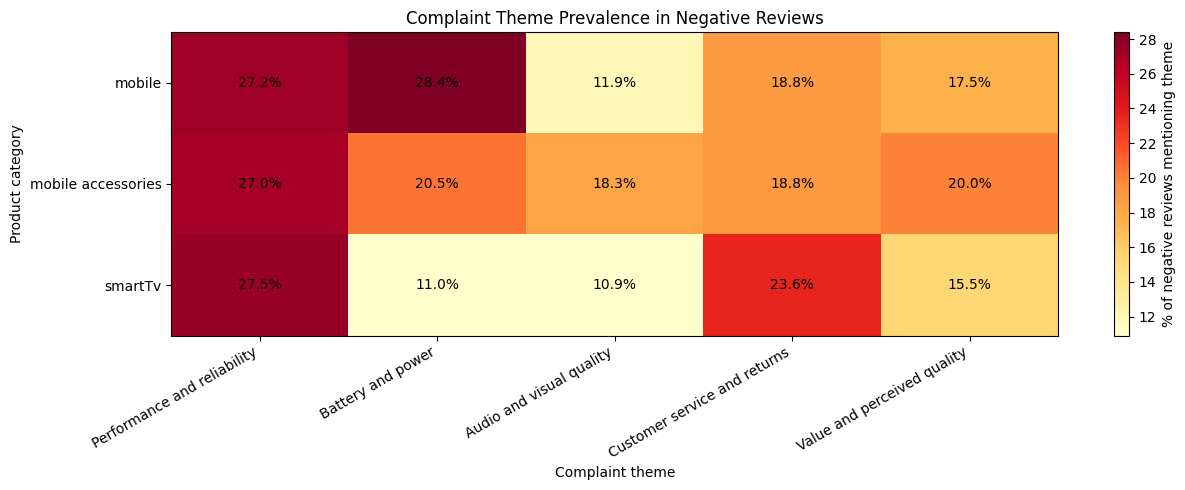

Theme,Performance and reliability,Battery and power,Audio and visual quality,Customer service and returns,Value and perceived quality
Category,,,,,
mobile,27.19,28.39,11.88,18.83,17.52
mobile accessories,26.97,20.53,18.27,18.84,20.03
smartTv,27.50,10.96,10.91,23.56,15.48


In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

theme_pivot = theme_summary.pivot(
    index="Category",
    columns="Theme",
    values="Share of negative reviews (%)"
)

# Order themes by a useful business-analysis sequence
theme_order = [
    "Performance and reliability",
    "Battery and power",
    "Audio and visual quality",
    "Customer service and returns",
    "Value and perceived quality"
]

theme_pivot = theme_pivot[theme_order]

fig, ax = plt.subplots(figsize=(13, 5))

image = ax.imshow(
    theme_pivot.values,
    aspect="auto",
    cmap="YlOrRd"
)

ax.set_xticks(range(len(theme_pivot.columns)))
ax.set_xticklabels(
    theme_pivot.columns,
    rotation=30,
    ha="right"
)

ax.set_yticks(range(len(theme_pivot.index)))
ax.set_yticklabels(theme_pivot.index)

# Display percentages inside each cell
for i in range(len(theme_pivot.index)):
    for j in range(len(theme_pivot.columns)):
        value = theme_pivot.iloc[i, j]
        ax.text(j, i, f"{value:.1f}%", ha="center", va="center")

ax.set_title("Complaint Theme Prevalence in Negative Reviews")
ax.set_xlabel("Complaint theme")
ax.set_ylabel("Product category")

fig.colorbar(image, ax=ax, label="% of negative reviews mentioning theme")
plt.tight_layout()
plt.show()

display(theme_pivot.round(2))


In [ ]:
print(theme_summary.columns.tolist())

['Category', 'Theme', 'Matching reviews', 'Negative reviews in category', 'Share of negative reviews (%)']


In [ ]:

# Complaint theme summary with counts and percentages
theme_counts = theme_summary[
    [
        "Category",
        "Theme",
        "Matching reviews",
        "Negative reviews in category",
        "Share of negative reviews (%)"
    ]
].copy()

theme_counts = theme_counts.sort_values(
    ["Category", "Share of negative reviews (%)"],
    ascending=[True, False]
)

display(theme_counts.round(2))


,Category,Theme,Matching reviews,Negative reviews in category,Share of negative reviews (%)
11,mobile,Battery and power,992,3494,28.39
10,mobile,Performance and reliability,950,3494,27.19
13,mobile,Customer service and returns,658,3494,18.83
14,mobile,Value and perceived quality,612,3494,17.52
12,mobile,Audio and visual quality,415,3494,11.88
0,mobile accessories,Performance and reliability,657,2436,26.97
1,mobile accessories,Battery and power,500,2436,20.53
4,mobile accessories,Value and perceived quality,488,2436,20.03
3,mobile accessories,Customer service and returns,459,2436,18.84
2,mobile accessories,Audio and visual quality,445,2436,18.27


In [ ]:

recommendations = pd.DataFrame([
    {
        "Category": "mobile",
        "Finding": "Battery and power",
        "Evidence": "992 reviews; 28.39% of negative reviews",
        "Recommended action": (
            "Investigate battery life, charging and power-related "
            "complaints; compare patterns across products."
        ),
        "Suggested KPI": "Battery-related complaint rate"
    },
    {
        "Category": "mobile accessories",
        "Finding": "Performance and reliability",
        "Evidence": "657 reviews; 26.97% of negative reviews",
        "Recommended action": (
            "Review recurring failure descriptions and prioritise "
            "quality checks for products with repeated complaints."
        ),
        "Suggested KPI": "Reliability complaint rate"
    },
    {
        "Category": "smartTv",
        "Finding": "Performance and reliability",
        "Evidence": "650 reviews; 27.50% of negative reviews",
        "Recommended action": (
            "Investigate product-functionality complaints and "
            "track service, repair and replacement feedback."
        ),
        "Suggested KPI": "Product-functionality complaint rate"
    },
    {
        "Category": "smartTv",
        "Finding": "Customer service and returns",
        "Evidence": "557 reviews; 23.56% of negative reviews",
        "Recommended action": (
            "Review installation, warranty, returns and support "
            "experiences to identify recurring service issues."
        ),
        "Suggested KPI": "Service-related complaint rate"
    }
])

display(recommendations)


,Category,Finding,Evidence,Recommended action,Suggested KPI
0,mobile,Battery and power,992 reviews; 28.39% of negative reviews,"Investigate battery life, charging and power-r...",Battery-related complaint rate
1,mobile accessories,Performance and reliability,657 reviews; 26.97% of negative reviews,Review recurring failure descriptions and prio...,Reliability complaint rate
2,smartTv,Performance and reliability,650 reviews; 27.50% of negative reviews,Investigate product-functionality complaints a...,Product-functionality complaint rate
3,smartTv,Customer service and returns,557 reviews; 23.56% of negative reviews,"Review installation, warranty, returns and sup...",Service-related complaint rate


In [ ]:

print(reviews["Own_Rating"].dtype)
print(reviews["Own_Rating"].value_counts(dropna=False).head(15))


object
Own_Rating
Positive    47433
Negative     9087
Neutral      4366
Name: count, dtype: int64


In [ ]:

# Convert rating values to numbers safely
reviews["Own_Rating"] = pd.to_numeric(
    reviews["Own_Rating"],
    errors="coerce"
)

# Check whether any values could not be converted
print("Missing or invalid ratings:", reviews["Own_Rating"].isna().sum())
print("Rating values:", sorted(reviews["Own_Rating"].dropna().unique()))


Missing or invalid ratings: 60886
Rating values: []


In [ ]:

project_kpis = pd.DataFrame([
    {
        "Area": "Dataset",
        "Metric": "Reviews retained after cleaning",
        "Result": f"{len(reviews):,}"
    },
    {
        "Area": "Sentiment distribution",
        "Metric": "Positive reviews",
        "Result": f"{reviews['Own_Rating'].isin([4, 5]).sum():,}"
    },
    {
        "Area": "Sentiment distribution",
        "Metric": "Neutral reviews",
        "Result": f"{reviews['Own_Rating'].eq(3).sum():,}"
    },
    {
        "Area": "Sentiment distribution",
        "Metric": "Negative reviews",
        "Result": f"{reviews['Own_Rating'].isin([1, 2]).sum():,}"
    },
    {
        "Area": "Model evaluation",
        "Metric": "Test accuracy",
        "Result": "84.32%"
    },
    {
        "Area": "Model evaluation",
        "Metric": "Test macro F1",
        "Result": "0.6779"
    },
    {
        "Area": "Model evaluation",
        "Metric": "Test weighted F1",
        "Result": "0.8581"
    },
    {
        "Area": "Business analysis",
        "Metric": "Categories examined",
        "Result": "3"
    }
])

display(project_kpis)


,Area,Metric,Result
0,Dataset,Reviews retained after cleaning,"60,886"
1,Sentiment distribution,Positive reviews,0
2,Sentiment distribution,Neutral reviews,0
3,Sentiment distribution,Negative reviews,0
4,Model evaluation,Test accuracy,84.32%
5,Model evaluation,Test macro F1,0.6779
6,Model evaluation,Test weighted F1,0.8581
7,Business analysis,Categories examined,3


In [ ]:

print("Data type:", reviews["Own_Rating"].dtype)
print("\nMost common values:")
print(reviews["Own_Rating"].value_counts(dropna=False).head(20))

print("\nSample values:")
print(reviews["Own_Rating"].head(15).tolist())


Data type: float64

Most common values:
Own_Rating
NaN    60886
Name: count, dtype: int64

Sample values:
[nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan]


In [ ]:

print("Original Own_Rating type:", df["Own_Rating"].dtype)
print("\nOriginal rating values:")
print(df["Own_Rating"].value_counts(dropna=False).head(20))


Original Own_Rating type: object

Original rating values:
Own_Rating
Positive    47436
Negative     9087
Neutral      4366
Name: count, dtype: int64


In [ ]:

# Restore the original sentiment labels from df
reviews["Own_Rating"] = df.loc[reviews.index, "Own_Rating"]

print(reviews["Own_Rating"].value_counts(dropna=False))


Own_Rating
Positive    47433
Negative     9087
Neutral      4366
Name: count, dtype: int64


In [ ]:

sentiment_counts = reviews["Own_Rating"].value_counts()

project_kpis = pd.DataFrame([
    {
        "Area": "Dataset",
        "Metric": "Reviews retained after cleaning",
        "Result": f"{len(reviews):,}"
    },
    {
        "Area": "Sentiment distribution",
        "Metric": "Positive reviews",
        "Result": f"{sentiment_counts.get('Positive', 0):,}"
    },
    {
        "Area": "Sentiment distribution",
        "Metric": "Neutral reviews",
        "Result": f"{sentiment_counts.get('Neutral', 0):,}"
    },
    {
        "Area": "Sentiment distribution",
        "Metric": "Negative reviews",
        "Result": f"{sentiment_counts.get('Negative', 0):,}"
    },
    {
        "Area": "Model evaluation",
        "Metric": "Test accuracy",
        "Result": "84.32%"
    },
    {
        "Area": "Model evaluation",
        "Metric": "Test macro F1",
        "Result": "0.6779"
    },
    {
        "Area": "Model evaluation",
        "Metric": "Test weighted F1",
        "Result": "0.8581"
    },
    {
        "Area": "Business analysis",
        "Metric": "Categories examined",
        "Result": "3"
    }
])

display(project_kpis)


,Area,Metric,Result
0,Dataset,Reviews retained after cleaning,"60,886"
1,Sentiment distribution,Positive reviews,"47,433"
2,Sentiment distribution,Neutral reviews,"4,366"
3,Sentiment distribution,Negative reviews,"9,087"
4,Model evaluation,Test accuracy,84.32%
5,Model evaluation,Test macro F1,0.6779
6,Model evaluation,Test weighted F1,0.8581
7,Business analysis,Categories examined,3


In [ ]:

print("Original sentiment counts:")
print(df["Own_Rating"].value_counts(dropna=False))

print("\nCleaned sentiment counts:")
print(reviews["Own_Rating"].value_counts(dropna=False))

print("\nCleaned dataset size:", len(reviews))
print("Missing sentiment labels:", reviews["Own_Rating"].isna().sum())
print("Duplicate review IDs:", reviews["Unique_ID"].duplicated().sum())


Original sentiment counts:
Own_Rating
Positive    47436
Negative     9087
Neutral      4366
Name: count, dtype: int64

Cleaned sentiment counts:
Own_Rating
Positive    47433
Negative     9087
Neutral      4366
Name: count, dtype: int64

Cleaned dataset size: 60886
Missing sentiment labels: 0
Duplicate review IDs: 0


In [ ]:

from pathlib import Path

# Create an output folder
output_dir = Path("ai_customer_review_intelligence")
output_dir.mkdir(exist_ok=True)

# Export cleaned dataset and KPI summary
reviews.to_csv(
    output_dir / "cleaned_customer_reviews.csv",
    index=False
)

project_kpis.to_csv(
    output_dir / "project_kpis.csv",
    index=False
)

# Export complaint theme analysis and recommendations
theme_summary.to_csv(
    output_dir / "complaint_theme_summary.csv",
    index=False
)

recommendations.to_csv(
    output_dir / "business_recommendations.csv",
    index=False
)

print("Exported files:")
for file_path in sorted(output_dir.iterdir()):
    print(f"{file_path.name}: {file_path.stat().st_size:,} bytes")


Exported files:
business_recommendations.csv: 900 bytes
cleaned_customer_reviews.csv: 21,650,329 bytes
complaint_theme_summary.csv: 869 bytes
project_kpis.csv: 369 bytes


In [ ]:

# Check which existing project results are available
required_objects = [
    "reviews",
    "model",
    "final_model",
    "y_test",
    "y_pred",
    "project_kpis",
    "theme_summary",
    "recommendations",
]

for name in required_objects:
    print(f"{name}: {'Available' if name in globals() else 'Not found'}")


reviews: Available
model: Available
final_model: Available
y_test: Available
y_pred: Not found
project_kpis: Available
theme_summary: Available
recommendations: Available


In [ ]:

# Inspect existing variables without modifying the model
for name in ["X_train", "X_test", "X", "y_train", "y_test",
             "model", "final_model", "tfidf", "tfidf_vectorizer",
             "X_train_tfidf", "X_test_tfidf"]:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}: type={type(obj).__name__}, "
              f"shape={getattr(obj, 'shape', 'N/A')}")

# Check the trained model's expected input dimensions
for name in ["model", "final_model"]:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}:")
        print("  class:", type(obj).__name__)
        print("  expects features:", getattr(obj, "n_features_in_", "unknown"))
        print("  fitted classes:", getattr(obj, "classes_", "unknown"))
        if hasattr(obj, "named_steps"):
            print("  pipeline steps:", list(obj.named_steps.keys()))



X_train: type=Series, shape=(48708,)

X_test: type=Series, shape=(12178,)

X: type=Series, shape=(60886,)

y_train: type=Series, shape=(48708,)

y_test: type=Series, shape=(12178,)

model: type=LogisticRegression, shape=N/A

final_model: type=LogisticRegression, shape=N/A

tfidf: type=TfidfVectorizer, shape=N/A

X_train_tfidf: type=csr_matrix, shape=(48708, 100000)

X_test_tfidf: type=csr_matrix, shape=(12178, 100000)

model:
  class: LogisticRegression
  expects features: 92697
  fitted classes: ['Negative' 'Neutral' 'Positive']

final_model:
  class: LogisticRegression
  expects features: 100000
  fitted classes: ['Negative' 'Neutral' 'Positive']


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Use the already-transformed test data
y_pred = final_model.predict(X_test_tfidf)

# Evaluate against the existing held-out labels
y_true = y_test.to_numpy()
labels = ["Negative", "Neutral", "Positive"]

metrics = {
    "model": "TF-IDF + Logistic Regression",
    "test_samples": len(y_true),
    "accuracy": accuracy_score(y_true, y_pred),
    "macro_f1": f1_score(y_true, y_pred, average="macro"),
    "weighted_f1": f1_score(y_true, y_pred, average="weighted"),
}

print("MODEL PERFORMANCE")
for key, value in metrics.items():
    if key == "accuracy":
        print(f"{key}: {value:.4f} ({value:.2%})")
    elif isinstance(value, (float, np.floating)):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_true, y_pred, labels=labels, zero_division=0
))

print("CONFUSION MATRIX")
cm = confusion_matrix(y_true, y_pred, labels=labels)
print(pd.DataFrame(
    cm,
    index=[f"Actual {x}" for x in labels],
    columns=[f"Predicted {x}" for x in labels]
))


MODEL PERFORMANCE
model: TF-IDF + Logistic Regression
test_samples: 12178
accuracy: 0.8432 (84.32%)
macro_f1: 0.6779
weighted_f1: 0.8581

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.74      0.83      0.78      1818
     Neutral       0.27      0.44      0.33       873
    Positive       0.96      0.88      0.92      9487

    accuracy                           0.84     12178
   macro avg       0.66      0.72      0.68     12178
weighted avg       0.88      0.84      0.86     12178

CONFUSION MATRIX
                 Predicted Negative  Predicted Neutral  Predicted Positive
Actual Negative                1511                221                  86
Actual Neutral                  256                381                 236
Actual Positive                 280                830                8377


In [ ]:

from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import zipfile

from google.colab import files

# Export folder
out = Path("ai_customer_review_intelligence_portfolio_assets")
out.mkdir(exist_ok=True)

# Inspect the actual result-table columns before plotting
print("theme_summary columns:", theme_summary.columns.tolist())
print(theme_summary.head())
print("\nRecommendations columns:", recommendations.columns.tolist())
print(recommendations.head())


theme_summary columns: ['Category', 'Theme', 'Matching reviews', 'Negative reviews in category', 'Share of negative reviews (%)']
             Category                         Theme  Matching reviews  \
0  mobile accessories   Performance and reliability               657   
1  mobile accessories             Battery and power               500   
2  mobile accessories      Audio and visual quality               445   
3  mobile accessories  Customer service and returns               459   
4  mobile accessories   Value and perceived quality               488   

   Negative reviews in category  Share of negative reviews (%)  
0                          2436                          26.97  
1                          2436                          20.53  
2                          2436                          18.27  
3                          2436                          18.84  
4                          2436                          20.03  

Recommendations columns: ['Category', 'F

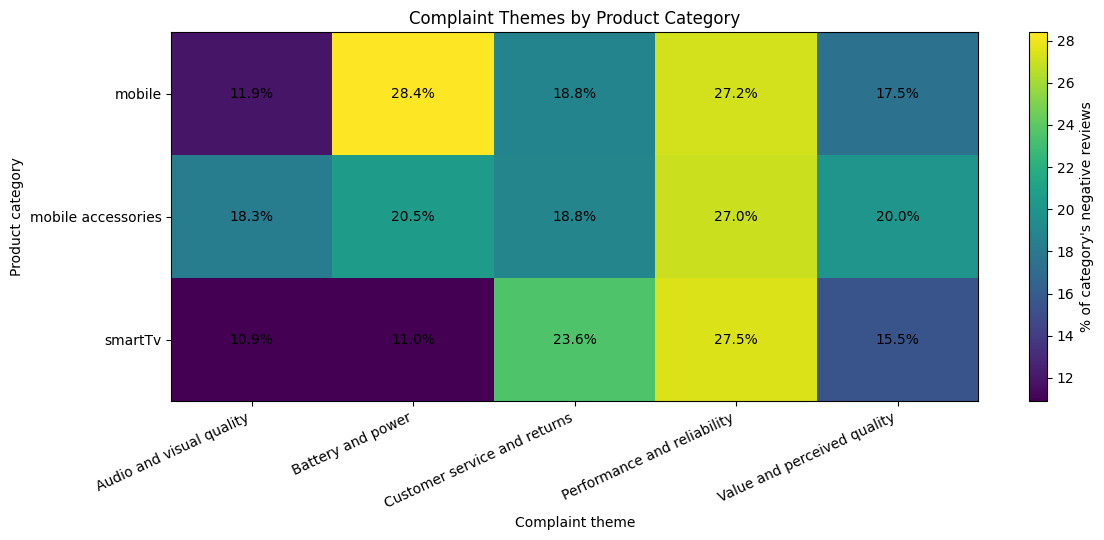

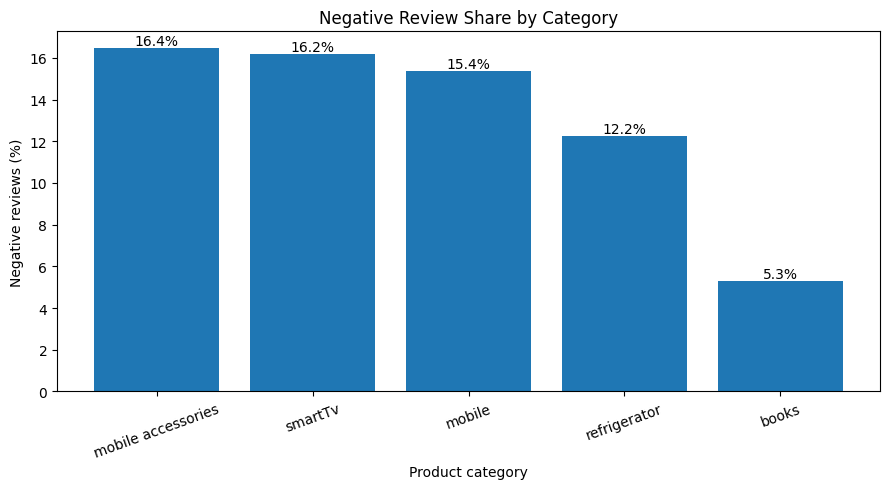

Created category and complaint-theme charts.
                    total_reviews  negative_reviews  negative_share_pct
Category                                                               
mobile accessories          14811              2436           16.447235
smartTv                     14624              2364           16.165208
mobile                      22746              3494           15.360943
refrigerator                 4791               586           12.231267
books                        3914               207            5.288707


In [ ]:

from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import zipfile
import json

from google.colab import files

out = Path("ai_customer_review_intelligence_portfolio_assets")
out.mkdir(exist_ok=True)

# 1. Complaint-theme heatmap
heatmap_data = theme_summary.pivot(
    index="Category",
    columns="Theme",
    values="Share of negative reviews (%)"
).fillna(0)

fig, ax = plt.subplots(figsize=(12, 5.5))
im = ax.imshow(heatmap_data.values, aspect="auto")
ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(
    heatmap_data.columns, rotation=25, ha="right"
)
ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)

for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):
        ax.text(
            j, i, f"{heatmap_data.iloc[i, j]:.1f}%",
            ha="center", va="center"
        )

ax.set_title("Complaint Themes by Product Category")
ax.set_xlabel("Complaint theme")
ax.set_ylabel("Product category")
fig.colorbar(im, ax=ax, label="% of category's negative reviews")
fig.tight_layout()
fig.savefig(out / "complaint_theme_heatmap.png", dpi=180,
            bbox_inches="tight")
plt.show()
plt.close(fig)

# 2. Negative-review share by category
category_counts = reviews.groupby("Category").agg(
    total_reviews=("Review_Content", "size"),
    negative_reviews=("Own_Rating",
                      lambda s: (s == "Negative").sum())
)
category_counts["negative_share_pct"] = (
    100 * category_counts["negative_reviews"]
    / category_counts["total_reviews"]
)
category_counts = category_counts.sort_values(
    "negative_share_pct", ascending=False
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(
    category_counts.index.astype(str),
    category_counts["negative_share_pct"]
)
ax.set_title("Negative Review Share by Category")
ax.set_ylabel("Negative reviews (%)")
ax.set_xlabel("Product category")
ax.tick_params(axis="x", rotation=20)
for i, v in enumerate(category_counts["negative_share_pct"]):
    ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom")
fig.tight_layout()
fig.savefig(out / "negative_review_share_by_category.png",
            dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

# Export the supporting aggregated tables
heatmap_data.to_csv(out / "complaint_theme_heatmap_data.csv")
category_counts.to_csv(out / "category_sentiment_summary.csv")

print("Created category and complaint-theme charts.")
print(category_counts)


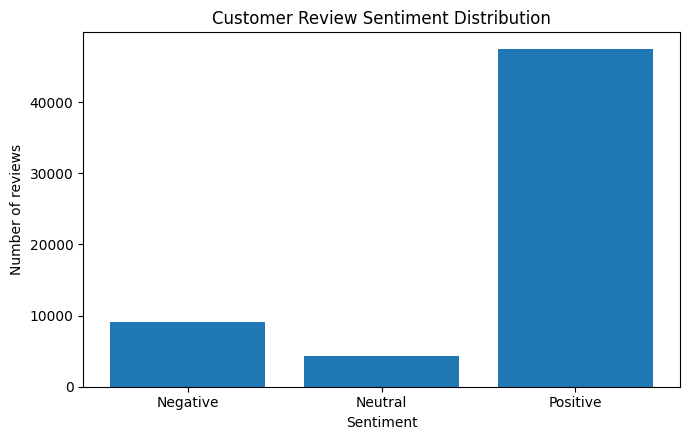

Files included:
- category_sentiment_summary.csv (256 bytes)
- classification_report.csv (486 bytes)
- complaint_theme_heatmap.png (157,652 bytes)
- complaint_theme_heatmap_data.csv (260 bytes)
- confusion_matrix.csv (141 bytes)
- model_metrics.json (175 bytes)
- negative_review_share_by_category.png (74,586 bytes)
- sentiment_distribution.csv (130 bytes)
- sentiment_distribution.png (39,862 bytes)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import json
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
from pathlib import Path
from google.colab import files

out = Path("ai_customer_review_intelligence_portfolio_assets")
out.mkdir(exist_ok=True)

# Verified metrics from the held-out test set
with open(out / "model_metrics.json", "w") as f:
    json.dump(
        {k: (float(v) if isinstance(v, (np.floating, np.integer))
             else v) for k, v in metrics.items()},
        f, indent=2
    )

# Per-class performance
report = pd.DataFrame(
    classification_report(
        y_test, y_pred, output_dict=True, zero_division=0
    )
).T
report.to_csv(out / "classification_report.csv")

# Confusion matrix
labels = ["Negative", "Neutral", "Positive"]
cm = confusion_matrix(y_test, y_pred, labels=labels)
pd.DataFrame(
    cm,
    index=[f"Actual {x}" for x in labels],
    columns=[f"Predicted {x}" for x in labels]
).to_csv(out / "confusion_matrix.csv")

# Sentiment distribution
sentiment = reviews["Own_Rating"].value_counts().reindex(
    labels, fill_value=0
)
sentiment_pct = sentiment / sentiment.sum() * 100

sentiment_table = pd.DataFrame({
    "Sentiment": labels,
    "Review count": sentiment.values,
    "Percentage": sentiment_pct.values
})
sentiment_table.to_csv(out / "sentiment_distribution.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(sentiment_table["Sentiment"], sentiment_table["Review count"])
ax.set_title("Customer Review Sentiment Distribution")
ax.set_ylabel("Number of reviews")
ax.set_xlabel("Sentiment")
fig.tight_layout()
fig.savefig(out / "sentiment_distribution.png", dpi=180,
            bbox_inches="tight")
plt.show()
plt.close(fig)

# Package all exported assets
zip_path = Path("ai_customer_review_intelligence_portfolio_assets.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in out.iterdir():
        if path.is_file() and path.suffix != ".zip":
            z.write(path, arcname=path.name)

print("Files included:")
for path in sorted(out.iterdir()):
    if path.is_file():
        print(f"- {path.name} ({path.stat().st_size:,} bytes)")

files.download(str(zip_path))
